# Rozdělení:

[Git - MSM](https://github.com/zcu-sediva/MSM/tree/master/ulohy/uloha1)

| Jméno | Úkol | Text |
| --- | --- | --- |
| Vitalij | 1. | Určení neznámé konstanty `c`|
| Vitalij | 2. | Marginální rozdělení|
| Marek | 3. | Teoretické charakteristiky|
| Marek | 4. | Generování dat |
| Marek | 5. | Odhady z generovaných dat|
| Vitalij | 6. | Porovnání s teoretickými funkcemi |
| Vitalij | 7. | Závislost odhadu na rozsahu výběru |



## 1. Určení neznámé konstanty

- Určete konstantu c tak, aby f(x, y) byla platnou hustotou pravděpodobnosti.

### Řešení 

- konstanta `c` spočítaná ručně. Jednodušší by bylo použít `sympy`.

$$



\begin{aligned}
1&=\int_1^2\int_1^y cxy\,dx\,dy\\
&=\frac c2\int_1^2 y(y^2-1)\,dy\\
&=\frac c2\left[\frac{y^4}{4}-\frac{y^2}{2}\right]_1^2\\
&=\frac{9c}{8}\\\\
c&=\frac{8}{9}
\end{aligned}

$$

In [29]:
%matplotlib widget

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.close("all")
plt.style.use("dark_background")

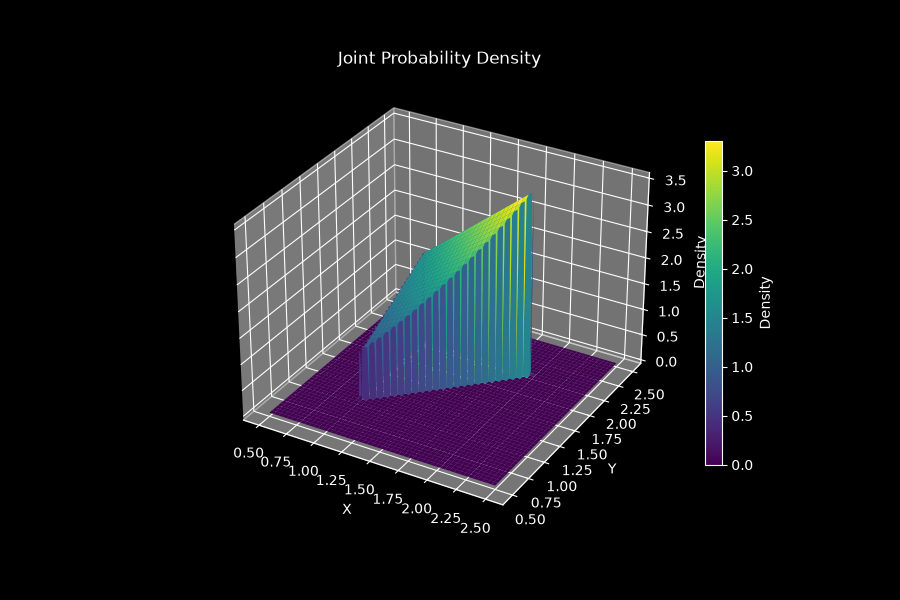

In [30]:
def density_function(x, y):
    return sp.Piecewise(
        (sp.Rational(8, 9) * x * y,
        (x > 1) & (x < y) & (y < 2)),
        (0, True)
    )

def create_plot(x_val, y_val, z_val):
    
    with plt.ioff():
        fig = plt.figure(figsize=(9, 6))
        
    ax = fig.add_subplot(111, projection="3d")
    
    surface = ax.plot_surface(x_val, y_val, z_val, cmap="viridis")

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Density")
    ax.set_title("Joint Probability Density")
    
    fig.colorbar(surface, ax=ax, label="Density", shrink=0.7)
    
    display(fig.canvas)
    
def plot_joint_density(f_xy):
    x, y = sp.symbols("x y", real=True)

    f = sp.lambdify((x, y), f_xy(x, y), "numpy")

    # Generate coordinates
    values = np.linspace(0.5, 2.5, 200)
    X, Y = np.meshgrid(values, values)

    # Calculate density at each point
    Z = f(X, Y)
    
    # Create 3D plot
    create_plot(X, Y, Z)
    
plot_joint_density(density_function)

In [31]:
"""
Calculation of marginal functions, marginal density functions and their visualizations
"""
def marginal_density_functions(f_xy):
    x, y  = sp.symbols("x y", real=True)
    
    f_x = sp.integrate(f_xy(x, y), (y, x, 2))
    f_y = sp.integrate(f_xy(x, y), (x, 1, y))
    
    f_x = sp.Piecewise(
        (f_x, (x > 1) & (x < 2)),
        (0, True)
    )

    f_y = sp.Piecewise(
        (f_y, (y > 1) & (y < 2)),
        (0, True)
    )
    
    return f_x, f_y

def marginal_distribution_functions(f_xy):
    x, y = sp.symbols("x y", real=True)
    t = sp.symbols("t", real=True)
    
    f_x, f_y = marginal_density_functions(f_xy)
    
    F_x = sp.Piecewise(
        (0, x <= 1),
        (sp.integrate(f_x.args[0].expr.subs(x, t), (t, 1, x)), x < 2),
        (1, True)
    )

    F_y = sp.Piecewise(
        (0, y <= 1),
        (sp.integrate(f_y.args[0].expr.subs(y, t), (t, 1, y)), y < 2),
        (1, True)
    )
    
    return F_x, F_y    

def visualize_marginals(f_x, f_y, F_x, F_y, values):
    # Outside the bound of the domain is effectively removed
    values[(values <= 1) | (values >= 2)] = np.nan
    
    x, y = sp.symbols("x y", real=True)
    
    fx = sp.lambdify(x, f_x, "numpy")
    fy = sp.lambdify(y, f_y, "numpy")
    Fx = sp.lambdify(x, F_x, "numpy")
    Fy = sp.lambdify(y, F_y, "numpy")
    
    # Create two plots side by side
    with plt.ioff():
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
    
    # Marginal PDFs
    ax1.plot(values, fx(values), label=r"$f_X(x)$")
    ax1.plot(values, fy(values), "--", label=r"$f_Y(y)$")
    ax1.set_title("Marginal Density Functions")
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Density")
    ax1.legend()
    ax1.grid(True)

    # Marginal CDFs
    ax2.plot(values, Fx(values), label=r"$F_X(x)$")
    ax2.plot(values, Fy(values), "--", label=r"$F_Y(y)$")
    ax2.set_title("Marginal Distribution Functions")
    ax2.set_xlabel("Value")
    ax2.set_ylabel("Cumulative Probability")
    ax2.legend()
    ax2.grid(True)

    fig.tight_layout()
    display(fig.canvas)    

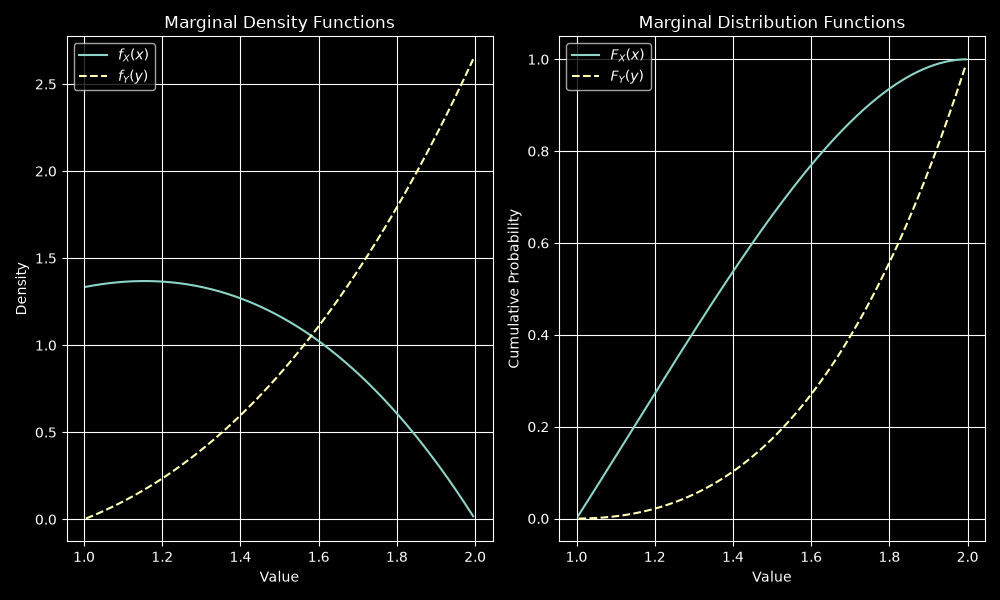

In [32]:
f_x, f_y = marginal_density_functions(density_function)
F_x, F_y = marginal_distribution_functions(density_function)

# TODO: doplnit generovani dat místo np.linspace(1, 2, 200)
visualize_marginals(f_x, f_y, F_x, F_y, np.linspace(1, 2, 200))

## Teoretické charakteristiky (střední hodnoty, rozptyly a kovariance (variační matici))

In [40]:
c = sp.Rational(8, 9)
x, y = sp.symbols('x y', real=True)
f = c * x * y

#print(f_x)
#print(f_y)

def calculate_mean():
    E_X = sp.integrate(x * f_x, (x, 1, 2))
    E_Y = sp.integrate(y * f_y, (y, 1, 2))
    return E_X, E_Y


def calculate_variance():
    E_X2 = sp.integrate((x**2) * f_x, (x, 1, 2))
    E_Y2 = sp.integrate((y**2) * f_y, (y, 1, 2))

    Var_X = E_X2 - E_X**2
    Var_Y = E_Y2 - E_Y**2

    return Var_X, Var_Y


def calculate_covariance():
    E_XY = sp.integrate(sp.integrate(x * y * f, (y, x, 2)), (x, 1, 2))
    Cov_XY = E_XY - E_X * E_Y
    return Cov_XY

def calculate_variance_matrix(Var_X, Var_Y, Cov_XY):
    Var_matrix = sp.Matrix([[Var_X, Cov_XY], [Cov_XY, Var_Y]])
    return Var_matrix


In [41]:
E_X, E_Y = calculate_mean()
Var_X, Var_Y = calculate_variance()
Cov_XY = calculate_covariance()
Var_matrix = calculate_variance_matrix(Var_X, Var_Y, Cov_XY)

print(f"Mean of X: {E_X}")
print(f"Mean of Y: {E_Y}")
print(f"Variance of X: {Var_X}")
print(f"Variance of Y: {Var_Y}")
print(f"Covariance of X and Y: {Cov_XY}")
print(f"Variance Matrix: {Var_matrix}")

Mean of X: 188/135
Mean of Y: 232/135
Variance of X: 1106/18225
Variance of Y: 851/18225
Covariance of X and Y: 484/18225
Variance Matrix: Matrix([[1106/18225, 484/18225], [484/18225, 851/18225]])


## Generování dat - zamítací metoda
#### dominující funkcí hustoty rovnoměrné rozdělení na intervalu <1,2> x <1,2>
#### konstanta *c* - maximální možná hodnota původní funkce

Míra přijetí: 0.2826 (teoreticky 0.2812)
Odhad E[X]: 1.3879 (teoreticky 1.3926)
Odhad E[Y]: 1.7146 (teoreticky 1.7185)
Odhad Var(X): 0.0602 (teoreticky 0.0607)
Odhad Var(Y): 0.0478 (teoreticky 0.0467)


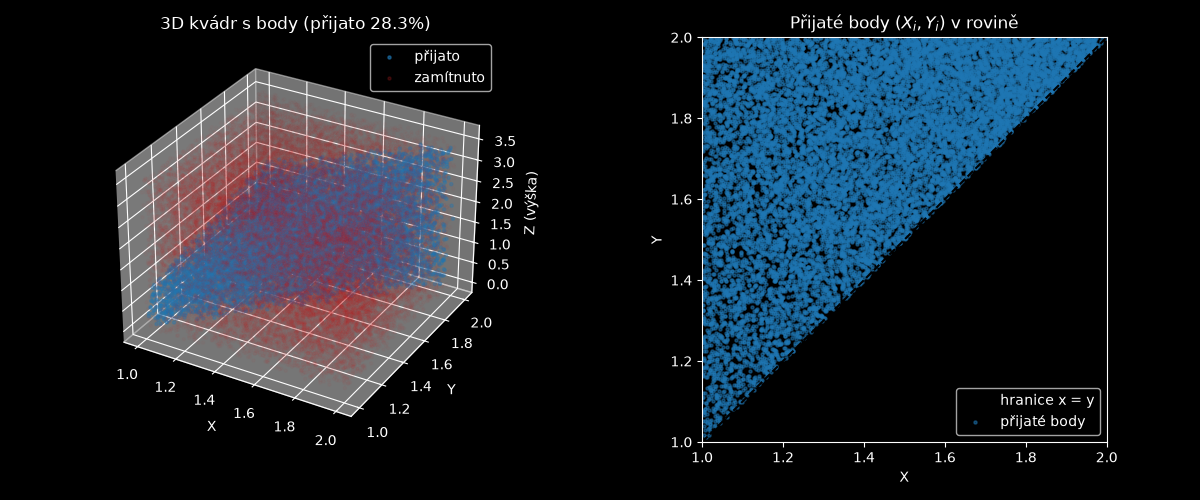

In [56]:
import numpy as np

rng = np.random.default_rng(42)
min = 1.0
max = 2.0
m = 50_000
c = (8/9)*max*max
x = rng.uniform(min, max, m)
y = rng.uniform(min, max, m)
z = rng.uniform(0, c, m)
accepted = (x <= y) & (z <= (8/9) * x * y)
x_acc = x[accepted]
y_acc = y[accepted]
print(f"Míra přijetí: {accepted.mean():.4f} (teoreticky {9/32:.4f})")
print(f"Odhad E[X]: {x_acc.mean():.4f} (teoreticky {float(E_X):.4f})")
print(f"Odhad E[Y]: {y_acc.mean():.4f} (teoreticky {float(E_Y):.4f})")
print(f"Odhad Var(X): {x_acc.var():.4f} (teoreticky {float(Var_X):.4f})")
print(f"Odhad Var(Y): {y_acc.var():.4f} (teoreticky {float(Var_Y):.4f})")

fig = plt.figure(figsize=(12, 5))

# 1. Graf: 3D kvádr bodů
ax1 = fig.add_subplot(121, projection="3d")
ax1.scatter(
    x[accepted],
    y[accepted],
    z[accepted],
    c="tab:blue",
    s=5,
    label="přijato",
    alpha=0.6,
)
ax1.scatter(
    x[~accepted],
    y[~accepted],
    z[~accepted],
    c="tab:red",
    s=5,
    label="zamítnuto",
    alpha=0.2,
)
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z (výška)")
ax1.set_title(f"3D kvádr s body (přijato {accepted.mean():.1%})")
ax1.legend()

# 2. Graf: 2D průmět přijatých bodů v rovině (X, Y)
ax2 = fig.add_subplot(122)
# Vykreslení hranice oblasti x <= y
ax2.plot(
    [min, max],
    [min, max],
    "k--",
    label="hranice x = y",
    linewidth=1.5,
)

ax2.scatter(
    x_acc[:m],
    y_acc[:m],
    c="tab:blue",
    s=5,
    alpha=0.5,
    label="přijaté body",
)
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_xlim(min, max)
ax2.set_ylim(min, max)
ax2.set_aspect("equal")
ax2.set_title("Přijaté body $(X_i, Y_i)$ v rovině")
ax2.legend()

plt.tight_layout()
plt.show()



## Intervalové odhady

In [57]:
from scipy import stats
n_acc = len(x_acc)
alpha = 0.05

#mean and standard deviation of accepted samples
x_mean = x_acc.mean()
x_std = x_acc.std(ddof=1)

y_mean = y_acc.mean()
y_std = y_acc.std(ddof=1)

#quantil of student distribution
t_crit = stats.t.ppf(1 - alpha / 2, df=n_acc - 1)

# confidence intervals for mean of x
x_lower_int = x_mean - t_crit * (x_std / np.sqrt(n_acc))
x_upper_int = x_mean + t_crit * (x_std / np.sqrt(n_acc))

# confidence intervals for mean of y
y_lower_int = y_mean - t_crit * (y_std / np.sqrt(n_acc))
y_upper_int = y_mean + t_crit * (y_std / np.sqrt(n_acc))

print(f"95% confidence interval for E[X]: ({x_lower_int:.4f}, {x_upper_int:.4f})")
print(f"Real value ≈ {188/135:.4f}")
print(f"95% confidence interval for E[Y]: ({y_lower_int:.4f}, {y_upper_int:.4f})")
print(f"Real value ≈ {232/135:.4f}")

chi_lower_crit = stats.chi2.ppf(alpha / 2, df=n_acc-1)
chi_upper_crit = stats.chi2.ppf(1 - alpha / 2, df=n_acc-1)
ci_lower_int = (n_acc - 1) * x_std**2 / chi_upper_crit
ci_upper_int = (n_acc - 1) * x_std**2 / chi_lower_crit
print(f"95% confidence interval for Var(X): ({ci_lower_int:.5f}, {ci_upper_int:.5f})")
print(f"Real value ≈ {1106/18225:.4f}")

95% confidence interval for E[X]: (1.3838, 1.3919)
Real value ≈ 1.3926
95% confidence interval for E[Y]: (1.7110, 1.7182)
Real value ≈ 1.7185
95% confidence interval for Var(X): (0.05886, 0.06167)
Real value ≈ 0.0607


In [54]:
def plot_empirical_vs_theoretical(
    x_samples, y_samples, f_x, f_y, F_x, F_y
):
    """
    Task 6:

    Parameters:
        x_samples, y_samples: NumPy arrays from Task 4
        f_x, f_y: SymPy marginal PDF expressions from Task 2
        F_x, F_y: SymPy marginal CDF expressions from Task 2
        
    -- USAGE
    
    f_x, f_y = marginal_density_functions(density_function)
    F_x, F_y = marginal_distribution_functions(density_function)
    x_samples, y_samples = generate_samples(n=10000)
 
 
    plot_empirical_vs_theoretical(f_x, f_y, F_x, F_y, x_samples, y_samples)
    
    """
    x, y = sp.symbols("x y", real=True)

    # Convert symbolic functions to NumPy functions
    fx = sp.lambdify(x, f_x, "numpy")
    fy = sp.lambdify(y, f_y, "numpy")
    Fx = sp.lambdify(x, F_x, "numpy")
    Fy = sp.lambdify(y, F_y, "numpy")

    grid = np.linspace(1, 2, 500)

    with plt.ioff():
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    for i, (samples, pdf, cdf, name) in enumerate([
        (x_samples, fx, Fx, "X"),
        (y_samples, fy, Fy, "Y")
    ]):
        samples = np.asarray(samples, dtype=float)

        # Histogram vs theoretical PDF
        axes[0, i].hist(
            samples, bins=30, density=True,
            alpha=0.5, label="Empirical histogram"
        )
        axes[0, i].plot(
            grid[1:-1], pdf(grid[1:-1]),
            label="Theoretical PDF"
        )
        axes[0, i].set_title(f"Marginal density {name}")
        axes[0, i].legend()
        axes[0, i].grid(True)

        # Empirical CDF vs theoretical CDF
        sorted_samples = np.sort(samples)
        ecdf = np.arange(1, len(samples) + 1) / len(samples)

        axes[1, i].step(
            sorted_samples, ecdf, where="post",
            label="Empirical CDF"
        )
        axes[1, i].plot(
            grid, cdf(grid),
            label="Theoretical CDF"
        )
        axes[1, i].set_title(f"Distribution function {name}")
        axes[1, i].legend()
        axes[1, i].grid(True)

    fig.tight_layout()
    display(fig.canvas)

In [55]:
def plot_estimation_accuracy(
    sample_sizes,
    estimates,
    confidence_intervals,
    theoretical_value,
    parameter_name="E[X]"
):
    """
    Task 7:

    Parameters:
        sample_sizes: Array of sample sizes
        estimates: Estimated parameter values from Task 5
        confidence_intervals: Array of (lower, upper) pairs
        theoretical_value: True value from Task 3
        parameter_name: Label for the estimated parameter
    """
    sample_sizes = np.asarray(sample_sizes)
    estimates = np.asarray(estimates)
    ci = np.asarray(confidence_intervals)

    if ci.shape != (len(sample_sizes), 2):
        raise ValueError("Expected confidence intervals of shape (n, 2)")

    errors = np.abs(estimates - theoretical_value)
    widths = ci[:, 1] - ci[:, 0]

    with plt.ioff():
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Estimation error
    ax1.plot(sample_sizes, errors, marker="o")
    ax1.set_title(f"Estimation error: {parameter_name}")
    ax1.set_xlabel("Sample size (n)")
    ax1.set_ylabel("Absolute error")
    ax1.grid(True)

    # Confidence interval widths
    ax2.plot(sample_sizes, widths, marker="o")
    ax2.set_title("Confidence interval width")
    ax2.set_xlabel("Sample size (n)")
    ax2.set_ylabel("Width")
    ax2.grid(True)

    fig.tight_layout()
    display(fig.canvas)

In [39]:
# TODO (Task 3):
# TODO (Task 4):
# TODO (Task 5):

# Expected data format for Task 7:
#
# sample_sizes = [100, 500, 1000, 5000]
# estimates = [mean_100, mean_500, mean_1000, mean_5000]
# confidence_intervals = [
#     (lower_100, upper_100),
#     (lower_500, upper_500),
#     (lower_1000, upper_1000),
#     (lower_5000, upper_5000),
# ]
#
# plot_estimation_accuracy(
#     sample_sizes,
#     estimates,
#     confidence_intervals,
#     theoretical_value=expected_x,
#     parameter_name="E[X]"
# )